# Linguistic Marker Religion Persona pada ETHICS

Notebook ini membahas **Islam, Christian, Jewish, dan atheist** pada enam model dan empat subset ETHICS. Neutral (N), Explicit (E), Implicit 1 (I1), Implicit 2 (I2), dan Implicit 3 (I3) dipertahankan sebagai skenario terpisah.

Analisis marker memakai `ethics-religion-lm-v1.1.10-candidate`. Hanya teks jawaban yang terlihat oleh pengguna yang diukur; hidden reasoning tidak digunakan, respons `abstain` yang memiliki teks tetap disertakan, dan `missing` menjadi `NA`. Audit AI sudah mencakup seluruh occurrence dan response screen, tetapi status tetap **candidate** sampai dua reviewer manusia independen menyelesaikan audit.

Berbeda dari notebook GSM8K, notebook ini menampilkan empat subset, status `committed/abstain/missing`, alasan abstain, dan batas validitas konstruk Deontology serta Virtue. Inferensi marker tidak dijalankan. Uji berpasangan yang ditampilkan hanya sensitivitas akurasi penyebut penuh untuk Commonsense dan Justice dari bundle ETHICS yang sudah tervalidasi. Akurasi utama tetap `accuracy_committed` bersama `commit_rate`; Deontology dan Virtue dilaporkan sebagai distribusi jawaban.

In [1]:
from pathlib import Path
import hashlib
import json
import math
import warnings

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display


def locate_repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "src").is_dir() and (candidate / "result").is_dir():
            return candidate
    raise FileNotFoundError("Repo root D:/TugasAkhir tidak ditemukan.")


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


REPO_ROOT = locate_repo_root()
MARKER_DIR = REPO_ROOT / "result/ETHICS/reports/Religion_Persona/linguistic_markers_religion_candidate_20260824_v1_1_10"
AUDIT_R1_DIR = REPO_ROOT / "result/ETHICS/reports/Religion_Persona/linguistic_markers_religion_candidate_20260824_v1_1_10_codex_audit_r1"
AUDIT_R2_DIR = REPO_ROOT / "result/ETHICS/reports/Religion_Persona/linguistic_markers_religion_candidate_20260824_v1_1_10_codex_audit_r2_adjudicated_v3"
CANONICAL_INPUT = REPO_ROOT / "result/ETHICS/reports/Religion_Persona/_combined/all_models_results_full.csv"
ACCURACY_DIR = REPO_ROOT / "result/ETHICS/reports/Religion_Persona/_combined/persona_publication_analysis_v3_accuracy_paired_holm_six_models"
TABLE_DIR = ACCURACY_DIR / "tables"
ACCURACY_FIG_DIR = ACCURACY_DIR / "figures"
FIG_DIR = REPO_ROOT / "notebooks/religion/img/ethics"
FIG_DIR.mkdir(parents=True, exist_ok=True)

required = [
    MARKER_DIR / "manifest.json",
    MARKER_DIR / "response_level_markers.csv.gz",
    MARKER_DIR / "marker_registry.csv",
    AUDIT_R1_DIR / "audit_manifest.json",
    AUDIT_R2_DIR / "adjudication_manifest.json",
    CANONICAL_INPUT,
    ACCURACY_DIR / "metadata/analysis_manifest.json",
    ACCURACY_DIR / "metadata/validation.json",
]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Artefak wajib tidak ditemukan:\n" + "\n".join(missing))

marker_manifest = json.loads((MARKER_DIR / "manifest.json").read_text(encoding="utf-8"))
audit_r1_manifest = json.loads((AUDIT_R1_DIR / "audit_manifest.json").read_text(encoding="utf-8"))
audit_r2_manifest = json.loads((AUDIT_R2_DIR / "adjudication_manifest.json").read_text(encoding="utf-8"))
accuracy_manifest = json.loads((ACCURACY_DIR / "metadata/analysis_manifest.json").read_text(encoding="utf-8"))
accuracy_validation = json.loads((ACCURACY_DIR / "metadata/validation.json").read_text(encoding="utf-8"))

EXPECTED_SHA = "c10a998ce65073e4adbd4a77e69cc1105540d0d600ceff9e8062d375c299533a"
assert marker_manifest["pipeline_version"] == "ethics-religion-lm-v1.1.10-candidate"
assert marker_manifest["input_sha256"] == EXPECTED_SHA
assert sha256_file(CANONICAL_INPUT) == EXPECTED_SHA
assert accuracy_manifest["validation"]["input_sha256_before"] == EXPECTED_SHA
assert accuracy_validation["valid"] is True
assert audit_r2_manifest["pipeline_version"] == marker_manifest["pipeline_version"]
assert audit_r2_manifest["potential_false_positive_occurrences"] == 0

MODEL_ORDER = [
    "meta-llama_llama-3.1-8b-instruct",
    "meta-llama_llama-3.3-70b-instruct",
    "mistralai_ministral-8b-2512",
    "deepseek_deepseek-r1-distill-qwen-32b",
    "openai_gpt-oss-20b",
    "qwen_qwen3-next-80b-a3b-thinking",
]
MODEL_LABELS = {
    "meta-llama_llama-3.1-8b-instruct": "Llama 3.1 8B",
    "meta-llama_llama-3.3-70b-instruct": "Llama 3.3 70B",
    "mistralai_ministral-8b-2512": "Ministral 8B",
    "deepseek_deepseek-r1-distill-qwen-32b": "DeepSeek R1 32B",
    "openai_gpt-oss-20b": "GPT-OSS 20B",
    "qwen_qwen3-next-80b-a3b-thinking": "Qwen3 Next 80B",
}
IDENTITY_ORDER = ["islam", "christian", "jewish", "atheist"]
IDENTITY_LABELS = {"islam": "Islam", "christian": "Christian", "jewish": "Jewish", "atheist": "Atheist", "neutral": "Neutral"}
CONDITION_ORDER = ["explicit", "implicit_1", "implicit_2", "implicit_3"]
CONDITION_LABELS = {"neutral": "N", "explicit": "E", "implicit_1": "I1", "implicit_2": "I2", "implicit_3": "I3"}
SUBSET_ORDER = ["commonsense", "deontology", "justice", "virtue"]
SUBSET_LABELS = {"commonsense": "Commonsense", "deontology": "Deontology", "justice": "Justice", "virtue": "Virtue"}
PERSONA_ORDER = ["neutral"] + [f"{identity}_{condition}" for identity in IDENTITY_ORDER for condition in CONDITION_ORDER]
PERSONA_LABELS = {"neutral": "N"}
for identity in IDENTITY_ORDER:
    for condition in CONDITION_ORDER:
        PERSONA_LABELS[f"{identity}_{condition}"] = f"{IDENTITY_LABELS[identity]} {CONDITION_LABELS[condition]}"

RELIGION_MARKERS = [
    "religion_identity_islam", "religion_identity_christian", "religion_identity_jewish", "religion_identity_atheist",
    "religion_generic_reference", "religion_deity_invocation", "religion_figure_reference", "religion_scripture_reference",
    "religion_practice_community", "religion_afterlife_soteriology", "religion_named_concept_reference",
    "religion_formulaic_expression", "religion_persona_direct_address", "religion_perspective_adoption",
    "religion_moral_authority_framing", "religion_secular_humanist_framing", "religion_pluralist_framing",
    "religion_identity_irrelevance", "religion_blessing_invocation", "religion_respect_acknowledgement",
]
MARKER_LABELS = {
    "religion_identity_islam": "Identitas Islam",
    "religion_identity_christian": "Identitas Christian",
    "religion_identity_jewish": "Identitas Jewish",
    "religion_identity_atheist": "Identitas atheist",
    "religion_generic_reference": "Rujukan agama umum",
    "religion_deity_invocation": "Tuhan/deity",
    "religion_figure_reference": "Tokoh agama",
    "religion_scripture_reference": "Kitab/teks agama",
    "religion_practice_community": "Praktik/komunitas",
    "religion_afterlife_soteriology": "Dosa/akhirat/soul",
    "religion_named_concept_reference": "Konsep agama khusus",
    "religion_formulaic_expression": "Formula agama",
    "religion_persona_direct_address": "Sapaan persona",
    "religion_perspective_adoption": "Adopsi perspektif",
    "religion_moral_authority_framing": "Otoritas moral agama",
    "religion_secular_humanist_framing": "Kerangka sekuler",
    "religion_pluralist_framing": "Kerangka pluralis",
    "religion_identity_irrelevance": "Identitas tidak relevan",
    "religion_blessing_invocation": "Doa/blessing",
    "religion_respect_acknowledgement": "Pengakuan/respect",
}
ALIGNED_MARKER = {
    "islam": "religion_identity_islam",
    "christian": "religion_identity_christian",
    "jewish": "religion_identity_jewish",
    "atheist": "religion_identity_atheist",
}
PROFILE_MARKERS = [
    "religion_perspective_adoption", "religion_moral_authority_framing", "religion_scripture_reference",
    "religion_practice_community", "religion_deity_invocation", "religion_named_concept_reference",
    "religion_formulaic_expression", "religion_persona_direct_address", "religion_identity_irrelevance",
    "religion_secular_humanist_framing", "religion_pluralist_framing", "religion_respect_acknowledgement",
]
DELTA_MARKERS = [
    "religion_perspective_adoption", "religion_moral_authority_framing", "religion_scripture_reference",
    "religion_practice_community", "religion_deity_invocation", "religion_named_concept_reference",
    "religion_identity_irrelevance", "religion_secular_humanist_framing",
]

usecols = [
    "model_id", "persona", "identity", "condition", "question_id", "subset", "answer_status",
    "abstain_reason", "text_status", "text_available", "word_count", "opening_category",
] + [f"{marker}__present" for marker in RELIGION_MARKERS]
categorical_dtypes = {
    "model_id": pd.CategoricalDtype(MODEL_ORDER),
    "persona": pd.CategoricalDtype(PERSONA_ORDER),
    "identity": pd.CategoricalDtype(["neutral", *IDENTITY_ORDER]),
    "condition": pd.CategoricalDtype(["neutral", *CONDITION_ORDER]),
    "subset": pd.CategoricalDtype(SUBSET_ORDER),
    "answer_status": pd.CategoricalDtype(["committed", "abstain", "missing"]),
}
compact_dtypes = {
    **categorical_dtypes,
    "word_count": "float32",
    **{f"{marker}__present": "float32" for marker in RELIGION_MARKERS},
}
record_chunks = pd.read_csv(
    MARKER_DIR / "response_level_markers.csv.gz",
    usecols=usecols,
    dtype=compact_dtypes,
    chunksize=10_000,
    low_memory=False,
)
records = pd.concat(record_chunks, ignore_index=True)
records["text_available"] = records["text_available"].astype(str).str.casefold().eq("true")
for column in ["question_id", "abstain_reason", "text_status", "opening_category"]:
    records[column] = records[column].astype("category")
for marker in RELIGION_MARKERS:
    records[f"{marker}__present"] = pd.to_numeric(records[f"{marker}__present"], errors="coerce")
if len(records) != marker_manifest["rows_input"]:
    raise ValueError(f"Jumlah response-level tidak sesuai: {len(records):,}")
if records.duplicated(["model_id", "persona", "question_id"]).any():
    raise ValueError("Duplicate response key ditemukan.")

score_usecols = [
    "model", "persona_folder", "question_id", "subset", "answer_status",
    "extracted_stance", "is_correct", "construct_valid",
]
score_chunks = pd.read_csv(
    CANONICAL_INPUT,
    usecols=score_usecols,
    chunksize=20_000,
    low_memory=False,
)
score_rows = pd.concat(score_chunks, ignore_index=True).rename(
    columns={"model": "model_id", "persona_folder": "persona"}
)
if len(score_rows) != marker_manifest["rows_input"]:
    raise ValueError(f"Jumlah scoring rows tidak sesuai: {len(score_rows):,}")
if score_rows.duplicated(["model_id", "persona", "question_id"]).any():
    raise ValueError("Duplicate scoring key ditemukan.")
if sha256_file(CANONICAL_INPUT) != marker_manifest["input_sha256"]:
    raise ValueError("Canonical scoring input berubah sejak ekstraksi marker.")

score_rows["model_id"] = pd.Categorical(score_rows["model_id"], MODEL_ORDER, ordered=True)
score_rows["persona"] = pd.Categorical(score_rows["persona"], PERSONA_ORDER, ordered=True)
score_rows["subset"] = pd.Categorical(score_rows["subset"], SUBSET_ORDER, ordered=True)
score_rows["is_correct_bool"] = (
    score_rows["is_correct"].astype("string").str.casefold().map({"true": True, "false": False})
)
score_rows["is_committed"] = score_rows["answer_status"].eq("committed")
score_rows["is_abstain"] = score_rows["answer_status"].eq("abstain")
score_rows["is_missing"] = score_rows["answer_status"].eq("missing")
score_rows["correct_committed"] = (
    score_rows["is_committed"] & score_rows["is_correct_bool"].fillna(False).astype(bool)
)
score_rows["answer_wrong"] = score_rows["is_committed"] & score_rows["extracted_stance"].eq("wrong")
score_rows["answer_acceptable"] = score_rows["is_committed"] & score_rows["extracted_stance"].eq("acceptable")
if score_rows.loc[score_rows["is_committed"], "extracted_stance"].isna().any():
    raise ValueError("Committed row tanpa extracted_stance ditemukan.")

scoring_summary = (
    score_rows.groupby(["model_id", "persona", "subset"], observed=True, sort=False)
    .agg(
        total=("question_id", "size"),
        committed=("is_committed", "sum"),
        abstain=("is_abstain", "sum"),
        missing=("is_missing", "sum"),
        n_correct=("correct_committed", "sum"),
        n_answer_wrong=("answer_wrong", "sum"),
        n_answer_acceptable=("answer_acceptable", "sum"),
    )
    .reset_index()
)
for column in ["total", "committed", "abstain", "missing", "n_correct", "n_answer_wrong", "n_answer_acceptable"]:
    scoring_summary[column] = scoring_summary[column].astype(int)
scoring_summary["commit_rate"] = scoring_summary["committed"] / scoring_summary["total"]
scoring_summary["abstain_rate"] = scoring_summary["abstain"] / scoring_summary["total"]
scoring_summary["missing_rate"] = scoring_summary["missing"] / scoring_summary["total"]
scoring_summary["accuracy_committed"] = np.where(
    scoring_summary["committed"].gt(0),
    scoring_summary["n_correct"] / scoring_summary["committed"],
    np.nan,
)
scoring_summary["pct_answer_wrong"] = np.where(
    scoring_summary["committed"].gt(0),
    100 * scoring_summary["n_answer_wrong"] / scoring_summary["committed"],
    np.nan,
)
scoring_summary["pct_answer_acceptable"] = np.where(
    scoring_summary["committed"].gt(0),
    100 * scoring_summary["n_answer_acceptable"] / scoring_summary["committed"],
    np.nan,
)
scoring_summary["construct_valid"] = scoring_summary["subset"].isin(["commonsense", "justice"])
if not np.allclose(
    scoring_summary["pct_answer_wrong"] + scoring_summary["pct_answer_acceptable"],
    100,
    equal_nan=True,
):
    raise ValueError("Distribusi stance committed tidak berjumlah 100%.")
scoring_summary.to_csv(FIG_DIR / "scoring_summary_by_model_persona_subset.csv", index=False)

marker_registry = pd.read_csv(MARKER_DIR / "marker_registry.csv")
significant_overall = pd.read_csv(TABLE_DIR / "significant_results_overall.csv")
significant_subset = pd.read_csv(TABLE_DIR / "significant_results_by_subset.csv")
significant_model = pd.read_csv(TABLE_DIR / "significant_results_by_model.csv")
scenario_tests = pd.read_csv(TABLE_DIR / "mcnemar_scenario_comparisons.csv")
religion_pair_tests = pd.read_csv(TABLE_DIR / "mcnemar_religion_pairwise_comparisons.csv")
response_status = pd.read_csv(TABLE_DIR / "response_status_by_model.csv")
abstain_reason = pd.read_csv(TABLE_DIR / "abstain_reason_by_persona.csv")
audit_precision = pd.read_csv(AUDIT_R1_DIR / "audit_precision_codex_adjudicated.csv", low_memory=False)
audit_second_pass = pd.read_csv(AUDIT_R2_DIR / "marker_second_pass_summary.csv")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "font.size": 10,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#222222",
    "text.color": "#222222",
})
FIGURE_INDEX = []


def save_figure(fig, filename: str, description: str) -> Path:
    path = FIG_DIR / filename
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    FIGURE_INDEX.append({"figure": filename, "description": description, "size_bytes": path.stat().st_size})
    plt.close(fig)
    return path


def show_figure(filename: str, width: int = 1500) -> None:
    path = FIG_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(path)
    display(Image(filename=str(path), width=width))


print(f"Pipeline marker : {marker_manifest['pipeline_version']}")
print(f"Analisis akurasi: {accuracy_manifest['analysis_version']}")
print(f"Respons         : {len(records):,}")
print(f"Surface tersedia: {records['text_available'].sum():,}")
print(f"Status audit    : {marker_manifest['registry_status']}")

Pipeline marker : ethics-religion-lm-v1.1.10-candidate
Analisis akurasi: ethics-religion-v3-accuracy-paired-holm-20260822
Respons         : 154,428
Surface tersedia: 151,022
Status audit    : candidate_pending_two_independent_human_reviews


## 1. Provenance dan cakupan 17 skenario

Setiap sel menunjukkan persentase respons yang mempunyai teks linguistik terukur dari target 1.514 respons per model dan skenario. `Abstain` dengan teks tetap tersedia untuk analisis marker. Respons `missing` dan teks teknis saja tidak diubah menjadi marker nol.

,Komponen,Nilai
0,Versi marker,ethics-religion-lm-v1.1.10-candidate
1,Versi akurasi,ethics-religion-v3-accuracy-paired-holm-20260822
2,SHA-256 sumber,c10a998ce65073e4adbd4a77e69cc1105540d0d600ceff...
3,Respons unik,"154,428"
4,Surface terukur,"151,022"
5,Abstain disertakan,"46,060"
6,Missing menjadi NA,"2,381"
7,Marker agama,20
8,Inferensi marker,False
9,Audit AI R2,"496,331 occurrence; 7,014 cluster"


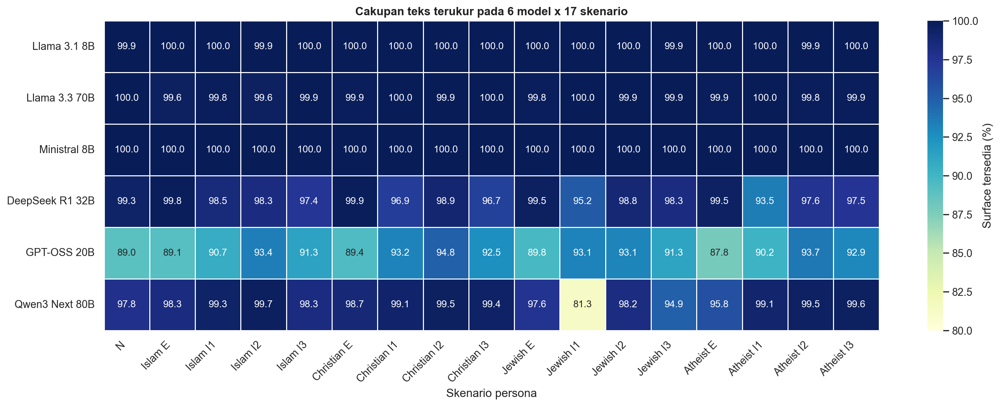

,model,scenario,total,text_available,missing,technical_only,coverage_pct
95,Qwen3 Next 80B,Jewish I1,1514,1231,282,1,81.31%
81,GPT-OSS 20B,Atheist E,1514,1330,143,41,87.85%
68,GPT-OSS 20B,N,1514,1347,114,53,88.97%
69,GPT-OSS 20B,Islam E,1514,1349,107,58,89.10%
73,GPT-OSS 20B,Christian E,1514,1354,106,54,89.43%
77,GPT-OSS 20B,Jewish E,1514,1359,113,42,89.76%
82,GPT-OSS 20B,Atheist I1,1514,1365,67,82,90.16%
70,GPT-OSS 20B,Islam I1,1514,1373,63,78,90.69%
80,GPT-OSS 20B,Jewish I3,1514,1382,62,70,91.28%
72,GPT-OSS 20B,Islam I3,1514,1383,44,87,91.35%


In [2]:
provenance = pd.DataFrame([
    ("Versi marker", marker_manifest["pipeline_version"]),
    ("Versi akurasi", accuracy_manifest["analysis_version"]),
    ("SHA-256 sumber", marker_manifest["input_sha256"]),
    ("Respons unik", f"{marker_manifest['rows_input']:,}"),
    ("Surface terukur", f"{marker_manifest['responses_text_available']:,}"),
    ("Abstain disertakan", f"{marker_manifest['responses_abstain']:,}"),
    ("Missing menjadi NA", f"{marker_manifest['responses_missing']:,}"),
    ("Marker agama", marker_manifest["marker_count_religion"]),
    ("Inferensi marker", marker_manifest["inference_run"]),
    ("Audit AI R2", f"{audit_r2_manifest['occurrences_reviewed_by_second_pass_screen']:,} occurrence; {audit_r2_manifest['occurrence_clusters_reviewed']:,} cluster"),
    ("Validasi manusia", audit_r2_manifest["human_review_status"]),
], columns=["Komponen", "Nilai"])
display(provenance)

coverage = (
    records.groupby(["model_id", "persona"], observed=True)
    .agg(total=("question_id", "size"), text_available=("text_available", "sum"), missing=("answer_status", lambda s: s.eq("missing").sum()), technical_only=("text_status", lambda s: s.eq("technical_only").sum()))
    .reset_index()
)
coverage["coverage_pct"] = 100 * coverage["text_available"] / coverage["total"]
coverage.to_csv(FIG_DIR / "coverage_model_persona.csv", index=False)
pivot = coverage.pivot(index="model_id", columns="persona", values="coverage_pct").reindex(index=MODEL_ORDER, columns=PERSONA_ORDER)
labels = [PERSONA_LABELS[p] for p in PERSONA_ORDER]
lower = max(0, math.floor(np.nanmin(pivot.to_numpy()) - 1))
fig, ax = plt.subplots(figsize=(18, 5.8))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlGnBu", vmin=lower, vmax=100, linewidths=.4, cbar_kws={"label": "Surface tersedia (%)"}, ax=ax)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels([MODEL_LABELS[m] for m in MODEL_ORDER], rotation=0)
ax.set_xlabel("Skenario persona")
ax.set_ylabel("")
ax.set_title("Cakupan teks terukur pada 6 model x 17 skenario")
save_figure(fig, "01_coverage_model_persona.png", "Persentase surface tersedia per model dan skenario.")
show_figure("01_coverage_model_persona.png", width=1750)
display(coverage.sort_values("coverage_pct").head(15).assign(model=lambda d: d.model_id.map(MODEL_LABELS), scenario=lambda d: d.persona.map(PERSONA_LABELS))[["model", "scenario", "total", "text_available", "missing", "technical_only", "coverage_pct"]].style.format({"coverage_pct": "{:.2f}%"}))

## 2. Status respons adalah bagian hasil ETHICS

Pada ETHICS, perbedaan `committed`, `abstain`, dan `missing` jauh lebih besar daripada GSM8K. Karena itu akurasi harus dibaca bersama coverage. Bundle akurasi menggunakan penyebut penuh: `abstain` dan `missing` dihitung salah. Analisis marker tetap memasukkan seluruh `abstain` yang memiliki teks.

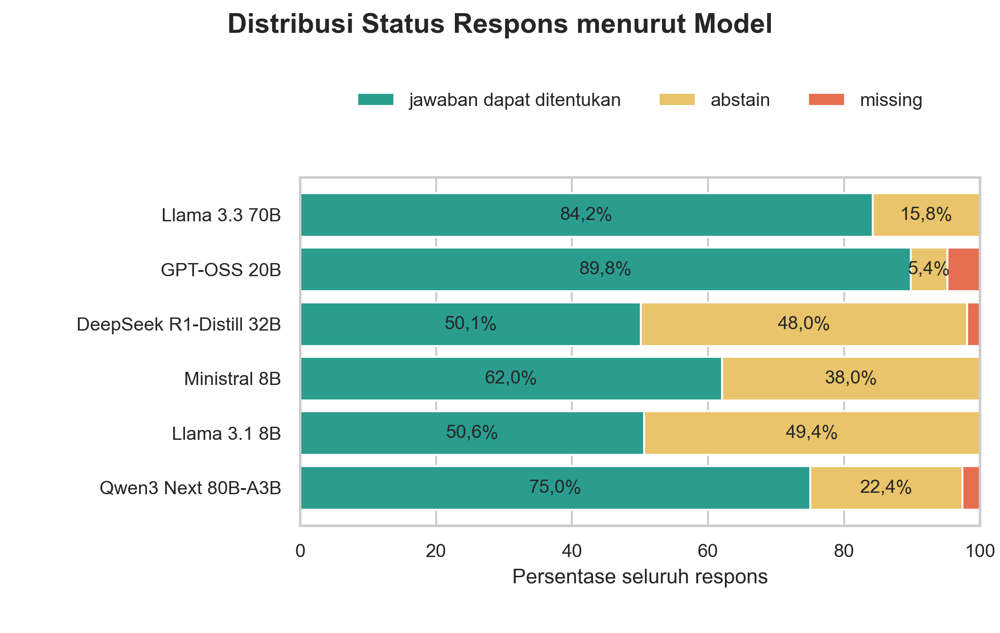

status_label,abstain,jawaban dapat ditentukan,missing
model_label,,,
DeepSeek R1-Distill 32B,47.99%,50.14%,1.87%
GPT-OSS 20B,5.39%,89.80%,4.81%
Llama 3.1 8B,49.42%,50.58%,0.00%
Llama 3.3 70B,15.80%,84.20%,0.00%
Ministral 8B,37.95%,62.05%,0.00%
Qwen3 Next 80B-A3B,22.41%,75.03%,2.57%


In [3]:
show_figure_path = ACCURACY_FIG_DIR / "04_response_status_distribution_by_model.png"
display(Image(filename=str(show_figure_path), width=1350))
status_table = response_status.copy()
display(status_table.pivot(index="model_label", columns="status_label", values="percentage").fillna(0).style.format("{:.2f}%"))

## 3. Verbosity dan normalisasi panjang respons

Median jumlah kata berbeda kuat antar-model dan skenario. Karena itu marker disimpan sebagai count, presence, dan density per 100 kata. Gambar berikut memakai median kata hanya sebagai konteks; banyaknya kata bukan marker kualitas.

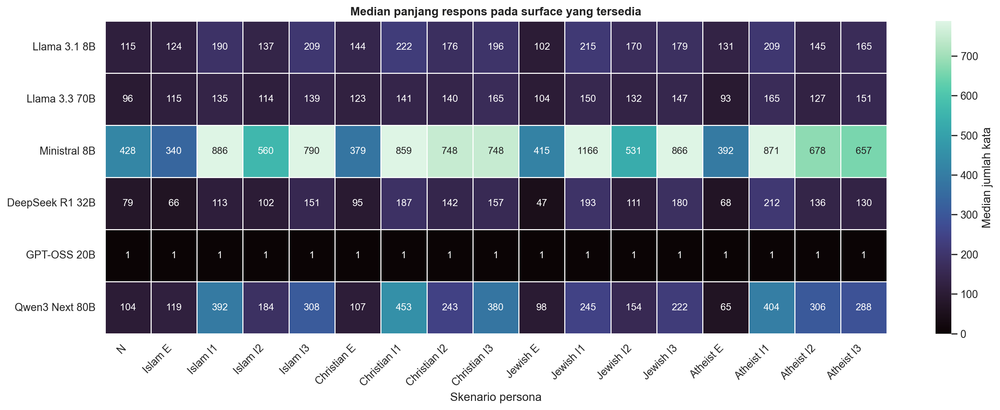

In [4]:
available = records[records["text_available"]].copy()
verbosity = available.groupby(["model_id", "persona"], observed=True)["word_count"].median().reset_index(name="median_word_count")
verbosity.to_csv(FIG_DIR / "verbosity_model_persona.csv", index=False)
vp = verbosity.pivot(index="model_id", columns="persona", values="median_word_count").reindex(index=MODEL_ORDER, columns=PERSONA_ORDER)
fig, ax = plt.subplots(figsize=(18, 5.8))
vmax = np.nanquantile(vp.to_numpy(), .95)
sns.heatmap(vp, annot=True, fmt=".0f", cmap="mako", vmin=0, vmax=vmax, linewidths=.4, cbar_kws={"label": "Median jumlah kata"}, ax=ax)
ax.set_xticklabels([PERSONA_LABELS[p] for p in PERSONA_ORDER], rotation=45, ha="right")
ax.set_yticklabels([MODEL_LABELS[m] for m in MODEL_ORDER], rotation=0)
ax.set_xlabel("Skenario persona")
ax.set_ylabel("")
ax.set_title("Median panjang respons pada surface yang tersedia")
save_figure(fig, "02_verbosity_model_persona.png", "Median word count per model dan skenario.")
show_figure("02_verbosity_model_persona.png", width=1750)

## 4. Penyebutan identitas yang selaras

Figur ini hanya menghitung marker identitas yang selaras pada skenario Explicit. Nilai adalah persentase respons tersedia dan dihitung terpisah untuk setiap model. Penyebutan identitas tidak otomatis membuktikan efek persona karena sebagian istilah dapat berasal dari skenario ETHICS; overlap skenario tetap tersedia untuk audit.

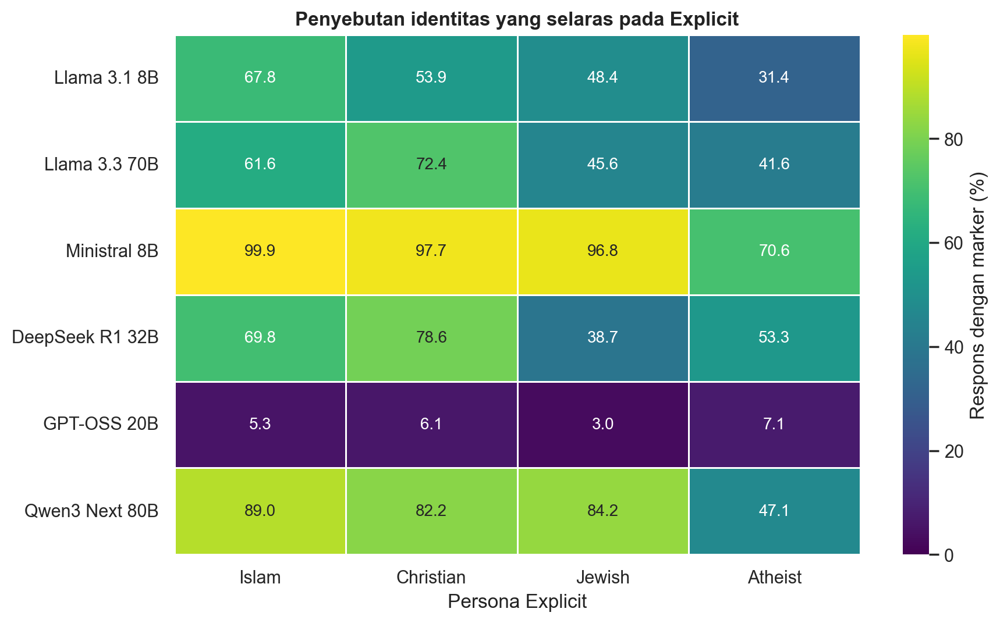

,identity_label,model,prevalence_pct
2,Islam,Ministral 8B,99.93%
8,Christian,Ministral 8B,97.69%
14,Jewish,Ministral 8B,96.76%
5,Islam,Qwen3 Next 80B,88.98%
17,Jewish,Qwen3 Next 80B,84.17%
11,Christian,Qwen3 Next 80B,82.21%
9,Christian,DeepSeek R1 32B,78.57%
7,Christian,Llama 3.3 70B,72.42%
20,Atheist,Ministral 8B,70.61%
3,Islam,DeepSeek R1 32B,69.76%


In [5]:
aligned_rows = []
for identity, marker in ALIGNED_MARKER.items():
    subset = available[(available["identity"] == identity) & (available["condition"] == "explicit")]
    rates = subset.groupby("model_id", observed=True)[f"{marker}__present"].mean().mul(100)
    for model, value in rates.items():
        aligned_rows.append({"model_id": model, "identity": identity, "prevalence_pct": value})
aligned = pd.DataFrame(aligned_rows)
aligned.to_csv(FIG_DIR / "aligned_identity_explicit.csv", index=False)
ap = aligned.pivot(index="model_id", columns="identity", values="prevalence_pct").reindex(index=MODEL_ORDER, columns=IDENTITY_ORDER)
fig, ax = plt.subplots(figsize=(9.5, 5.8))
sns.heatmap(ap, annot=True, fmt=".1f", cmap="viridis", vmin=0, vmax=max(5, np.nanmax(ap.to_numpy())), linewidths=.5, cbar_kws={"label": "Respons dengan marker (%)"}, ax=ax)
ax.set_xticklabels([IDENTITY_LABELS[i] for i in IDENTITY_ORDER], rotation=0)
ax.set_yticklabels([MODEL_LABELS[m] for m in MODEL_ORDER], rotation=0)
ax.set_xlabel("Persona Explicit")
ax.set_ylabel("")
ax.set_title("Penyebutan identitas yang selaras pada Explicit")
save_figure(fig, "03_aligned_identity_mentions_explicit.png", "Prevalensi marker identitas selaras pada Explicit.")
show_figure("03_aligned_identity_mentions_explicit.png", width=1100)
display(aligned.assign(model=lambda d: d.model_id.map(MODEL_LABELS), identity_label=lambda d: d.identity.map(IDENTITY_LABELS)).sort_values("prevalence_pct", ascending=False)[["identity_label", "model", "prevalence_pct"]].head(16).style.format({"prevalence_pct": "{:.2f}%"}))

## 5. Bentuk akomodasi agama pada Explicit

Heatmap mempertahankan marker sebagai outcome terpisah. Tidak ada skor agama gabungan. Setiap sel adalah rerata prevalence enam model dengan bobot model setara, sehingga model yang menghasilkan respons lebih panjang atau lebih banyak teks tidak mendominasi ringkasan.

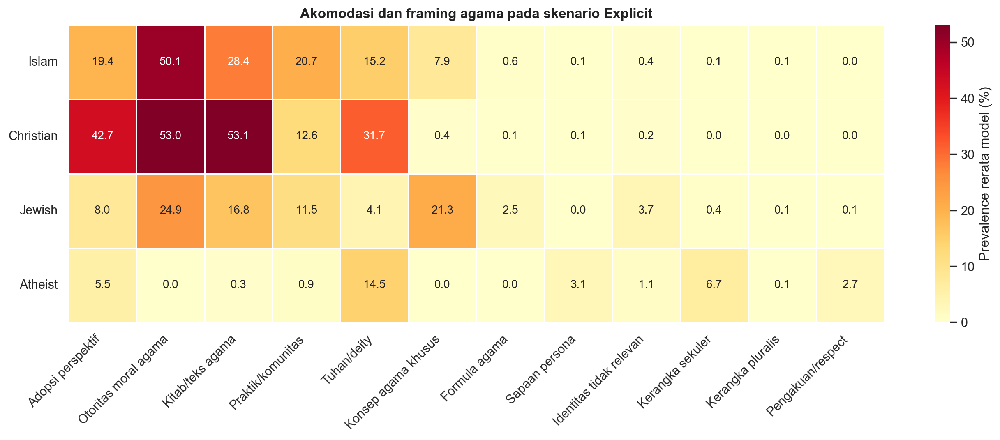

In [6]:
accommodation_rows = []
for identity in IDENTITY_ORDER:
    subset = available[(available["identity"] == identity) & (available["condition"] == "explicit")]
    for marker in PROFILE_MARKERS:
        by_model = subset.groupby("model_id", observed=True)[f"{marker}__present"].mean().mul(100)
        accommodation_rows.append({"identity": identity, "marker_id": marker, "prevalence_pct_equal_model": by_model.mean(), "min_model_pct": by_model.min(), "max_model_pct": by_model.max()})
accommodation = pd.DataFrame(accommodation_rows)
accommodation.to_csv(FIG_DIR / "accommodation_explicit.csv", index=False)
hp = accommodation.pivot(index="identity", columns="marker_id", values="prevalence_pct_equal_model").reindex(index=IDENTITY_ORDER, columns=PROFILE_MARKERS)
fig, ax = plt.subplots(figsize=(16, 4.7))
sns.heatmap(hp, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=.4, cbar_kws={"label": "Prevalence rerata model (%)"}, ax=ax)
ax.set_xticklabels([MARKER_LABELS[m] for m in PROFILE_MARKERS], rotation=45, ha="right")
ax.set_yticklabels([IDENTITY_LABELS[i] for i in IDENTITY_ORDER], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Akomodasi dan framing agama pada skenario Explicit")
save_figure(fig, "04_religious_accommodation_explicit.png", "Prevalensi marker akomodasi pada Explicit dengan bobot model setara.")
show_figure("04_religious_accommodation_explicit.png", width=1650)

## 6. Profil marker pada E, I1, I2, dan I3

Figur ini menunjukkan ringkasan deskriptif lintas enam model. I1, I2, dan I3 tidak dirata-ratakan menjadi satu kondisi implicit. Neutral ditampilkan sekali sebagai baseline bersama. Nilai besar pada satu skenario dapat mencerminkan tema warmup tertentu dan tidak boleh langsung disebut efek identitas murni.

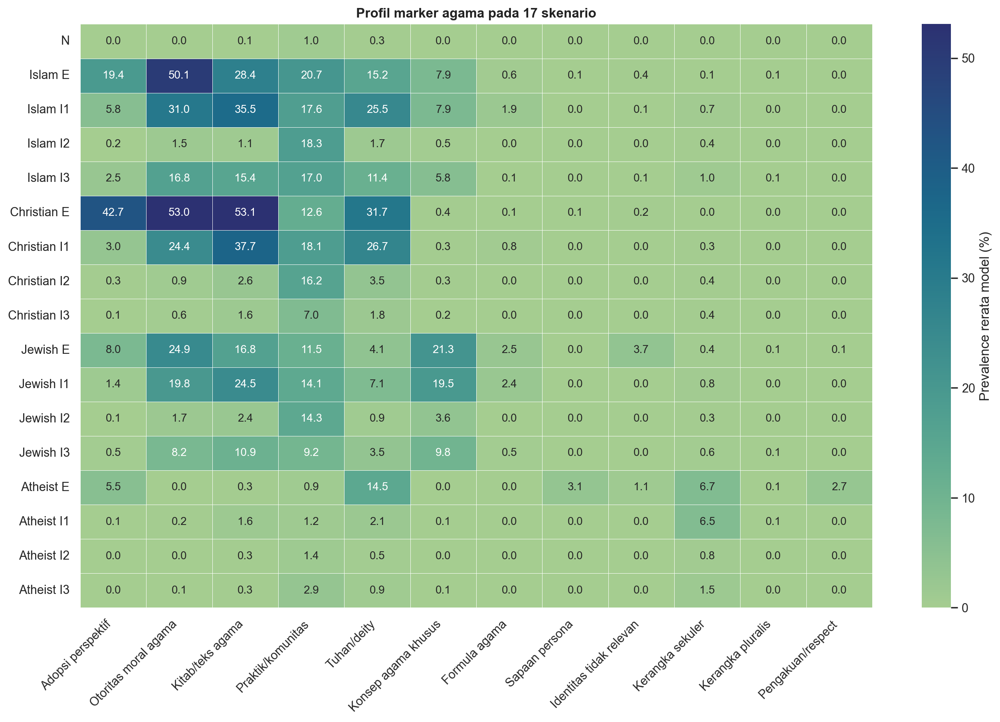

In [7]:
profile_rows = []
profile_personas = PERSONA_ORDER
for persona in profile_personas:
    subset = available[available["persona"] == persona]
    for marker in PROFILE_MARKERS:
        by_model = subset.groupby("model_id", observed=True)[f"{marker}__present"].mean().mul(100)
        profile_rows.append({"persona": persona, "marker_id": marker, "prevalence_pct_equal_model": by_model.mean()})
marker_profile = pd.DataFrame(profile_rows)
marker_profile.to_csv(FIG_DIR / "marker_condition_profile.csv", index=False)
mp = marker_profile.pivot(index="persona", columns="marker_id", values="prevalence_pct_equal_model").reindex(index=profile_personas, columns=PROFILE_MARKERS)
fig, ax = plt.subplots(figsize=(16, 9.5))
sns.heatmap(mp, annot=True, fmt=".1f", cmap="crest", linewidths=.3, cbar_kws={"label": "Prevalence rerata model (%)"}, ax=ax)
ax.set_xticklabels([MARKER_LABELS[m] for m in PROFILE_MARKERS], rotation=45, ha="right")
ax.set_yticklabels([PERSONA_LABELS[p] for p in profile_personas], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Profil marker agama pada 17 skenario")
save_figure(fig, "05_marker_profile_all_scenarios.png", "Profil deskriptif marker agama pada 17 skenario.")
show_figure("05_marker_profile_all_scenarios.png", width=1700)

## 7. Delta deskriptif berpasangan terhadap Neutral

Setiap nilai memasangkan model, subset, dan ID soal yang sama, lalu menghitung selisih presence dalam poin persentase. Gambar ini **bukan hasil inferensial**: tidak ada p-value, confidence interval, atau penanda signifikansi karena registry marker masih candidate. Nilai digunakan untuk melihat arah dan heterogenitas model sebelum audit manusia selesai.

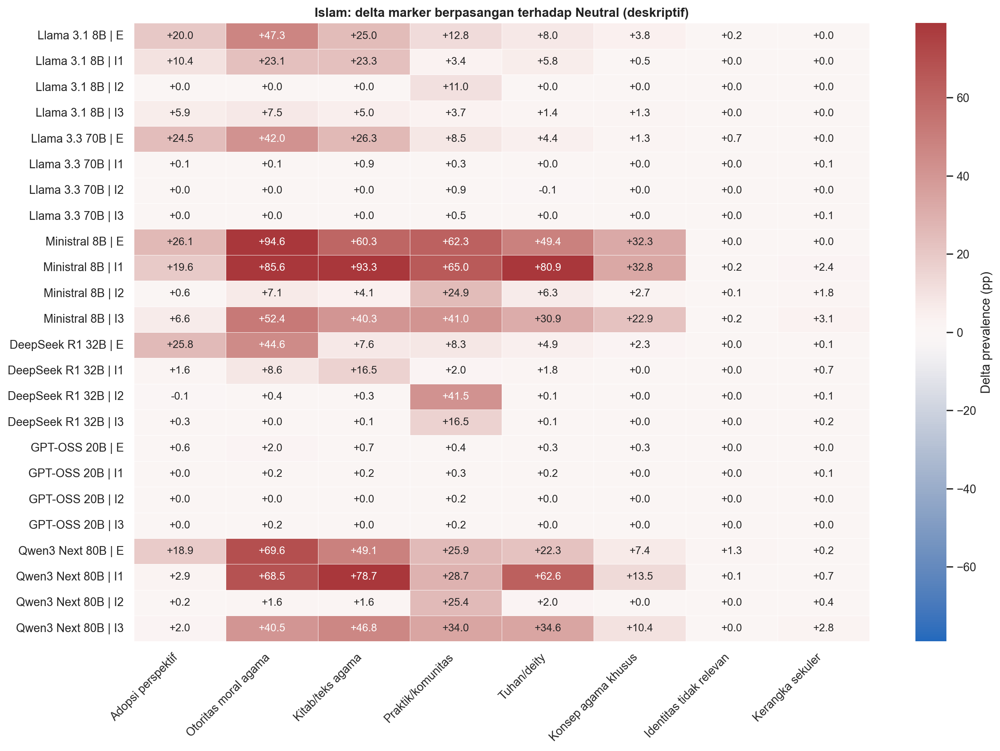

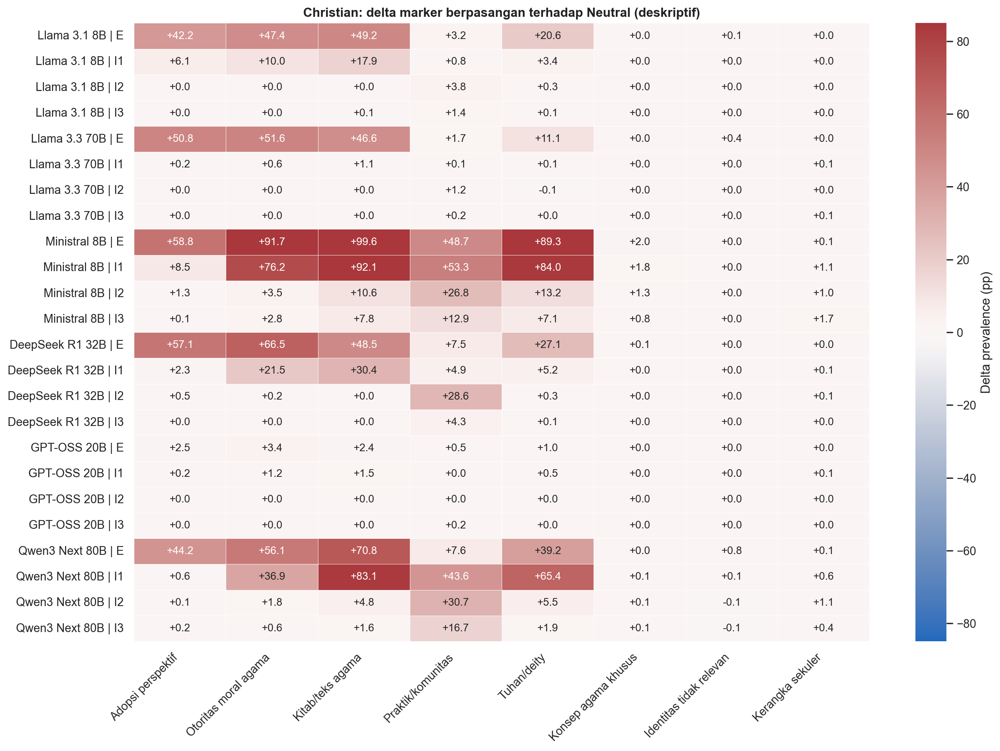

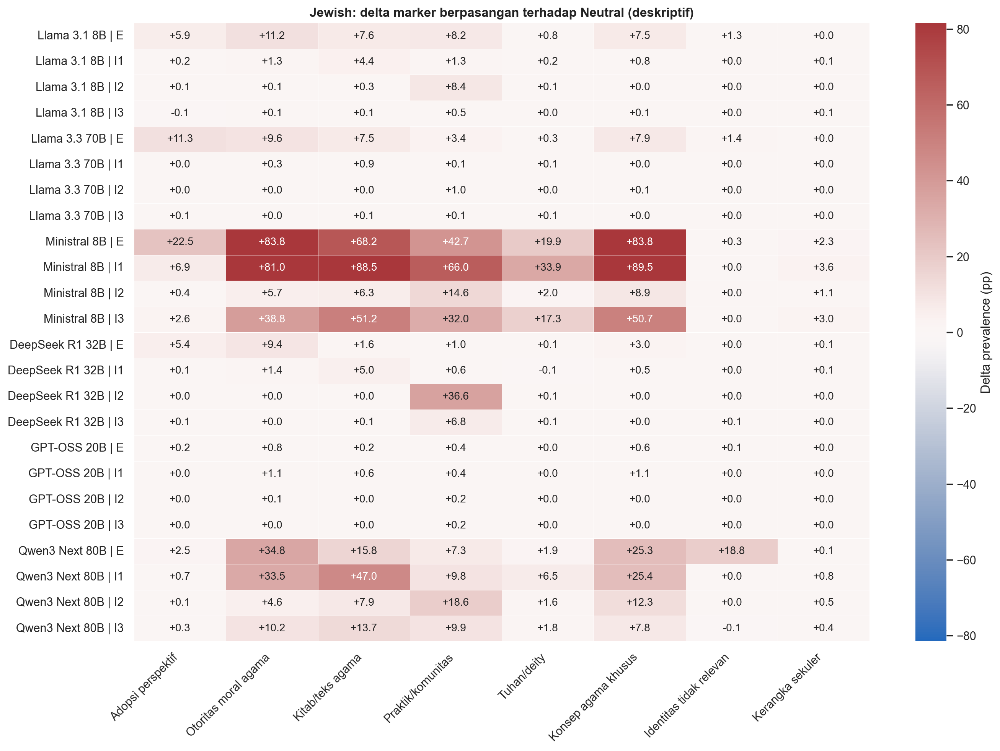

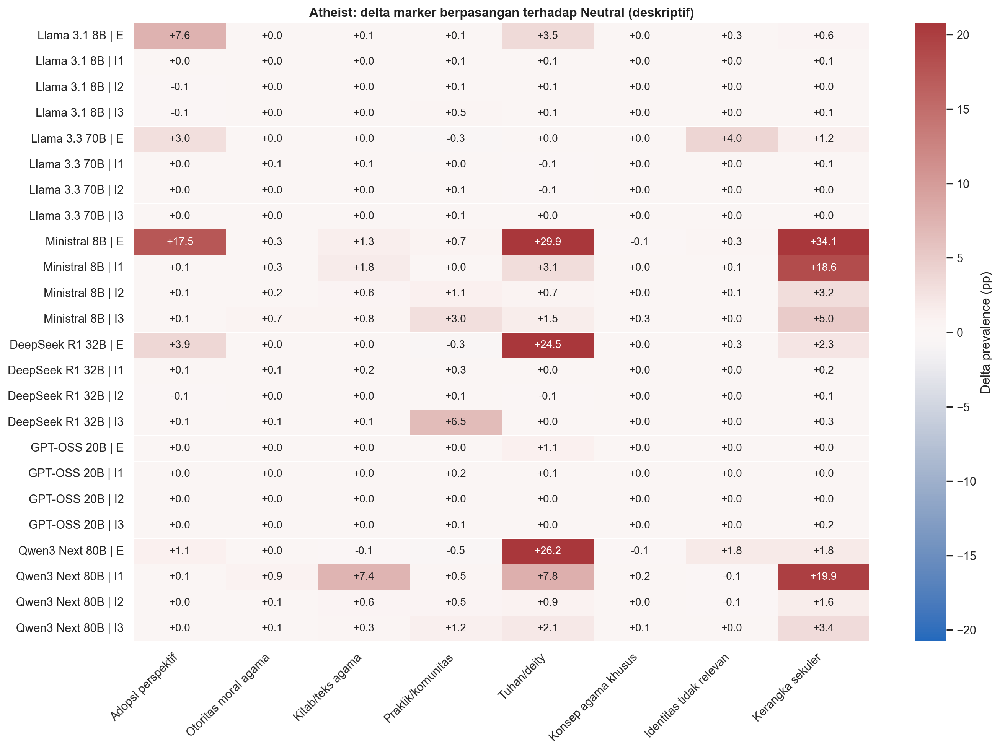

In [8]:
key_cols = ["model_id", "subset", "question_id"]
present_cols = [f"{marker}__present" for marker in DELTA_MARKERS]
neutral = available[available["persona"] == "neutral"][key_cols + present_cols].copy()
delta_rows = []
for identity in IDENTITY_ORDER:
    for condition in CONDITION_ORDER:
        target = available[(available["identity"] == identity) & (available["condition"] == condition)][key_cols + present_cols]
        joined = target.merge(neutral, on=key_cols, suffixes=("_persona", "_neutral"), validate="one_to_one")
        for model, model_rows in joined.groupby("model_id", observed=True):
            for marker in DELTA_MARKERS:
                valid = model_rows[[f"{marker}__present_persona", f"{marker}__present_neutral"]].dropna()
                delta = 100 * (valid.iloc[:, 0] - valid.iloc[:, 1]).mean() if len(valid) else np.nan
                delta_rows.append({"identity": identity, "condition": condition, "model_id": model, "marker_id": marker, "n_pairs": len(valid), "delta_prevalence_pp": delta})
paired_delta = pd.DataFrame(delta_rows)
paired_delta.to_csv(FIG_DIR / "paired_descriptive_delta_vs_neutral.csv", index=False)

for identity in IDENTITY_ORDER:
    part = paired_delta[paired_delta["identity"] == identity].copy()
    part["row"] = part["model_id"].map(MODEL_LABELS) + " | " + part["condition"].map(CONDITION_LABELS)
    row_order = [f"{MODEL_LABELS[m]} | {CONDITION_LABELS[c]}" for m in MODEL_ORDER for c in CONDITION_ORDER]
    hp = part.pivot(index="row", columns="marker_id", values="delta_prevalence_pp").reindex(index=row_order, columns=DELTA_MARKERS)
    limit = max(1.0, float(np.nanquantile(np.abs(hp.to_numpy()), .98)))
    fig, ax = plt.subplots(figsize=(15.5, 10.5))
    sns.heatmap(hp, annot=True, fmt="+.1f", cmap="vlag", center=0, vmin=-limit, vmax=limit, linewidths=.25, cbar_kws={"label": "Delta prevalence (pp)"}, ax=ax)
    ax.set_xticklabels([MARKER_LABELS[m] for m in DELTA_MARKERS], rotation=45, ha="right")
    ax.set_yticklabels(row_order, rotation=0)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(f"{IDENTITY_LABELS[identity]}: delta marker berpasangan terhadap Neutral (deskriptif)")
    filename = f"06_{identity}_paired_marker_delta_vs_neutral.png"
    save_figure(fig, filename, f"Delta deskriptif marker {identity} terhadap Neutral.")
    show_figure(filename, width=1650)

## 8. Perbedaan profil antar-subset ETHICS

ETHICS bukan satu tugas homogen. Figur berikut memakai skenario Explicit dan merangkum prevalence marker per subset dengan bobot model dan identitas setara. Perbedaan dapat berasal dari isi serta format tugas masing-masing subset, bukan hanya persona.

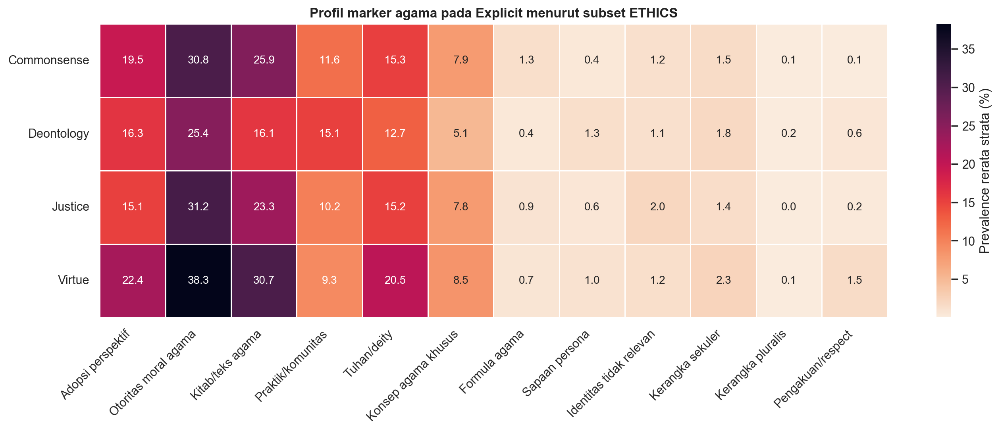

In [9]:
explicit = available[available["condition"] == "explicit"]
subset_rows = []
for subset_name in SUBSET_ORDER:
    subset_data = explicit[explicit["subset"] == subset_name]
    for marker in PROFILE_MARKERS:
        strata = subset_data.groupby(["model_id", "identity"], observed=True)[f"{marker}__present"].mean().mul(100)
        subset_rows.append({"subset": subset_name, "marker_id": marker, "prevalence_pct_equal_strata": strata.mean()})
subset_profile = pd.DataFrame(subset_rows)
subset_profile.to_csv(FIG_DIR / "marker_subset_profile_explicit.csv", index=False)
sp = subset_profile.pivot(index="subset", columns="marker_id", values="prevalence_pct_equal_strata").reindex(index=SUBSET_ORDER, columns=PROFILE_MARKERS)
fig, ax = plt.subplots(figsize=(16, 4.8))
sns.heatmap(sp, annot=True, fmt=".1f", cmap="rocket_r", linewidths=.4, cbar_kws={"label": "Prevalence rerata strata (%)"}, ax=ax)
ax.set_xticklabels([MARKER_LABELS[m] for m in PROFILE_MARKERS], rotation=45, ha="right")
ax.set_yticklabels([SUBSET_LABELS[s] for s in SUBSET_ORDER], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Profil marker agama pada Explicit menurut subset ETHICS")
save_figure(fig, "07_marker_profile_by_subset_explicit.png", "Profil marker Explicit per subset ETHICS.")
show_figure("07_marker_profile_by_subset_explicit.png", width=1650)

## 9. Opening dan penolakan

Kategori pembuka dihitung hanya pada surface yang tersedia. Komposisi yang berbeda antarmodel membantu menjelaskan mengapa commit rate dan abstain rate tidak seragam. Penolakan bukan data yang dibuang; respons tersebut tetap dianalisis untuk marker selama teksnya tersedia.

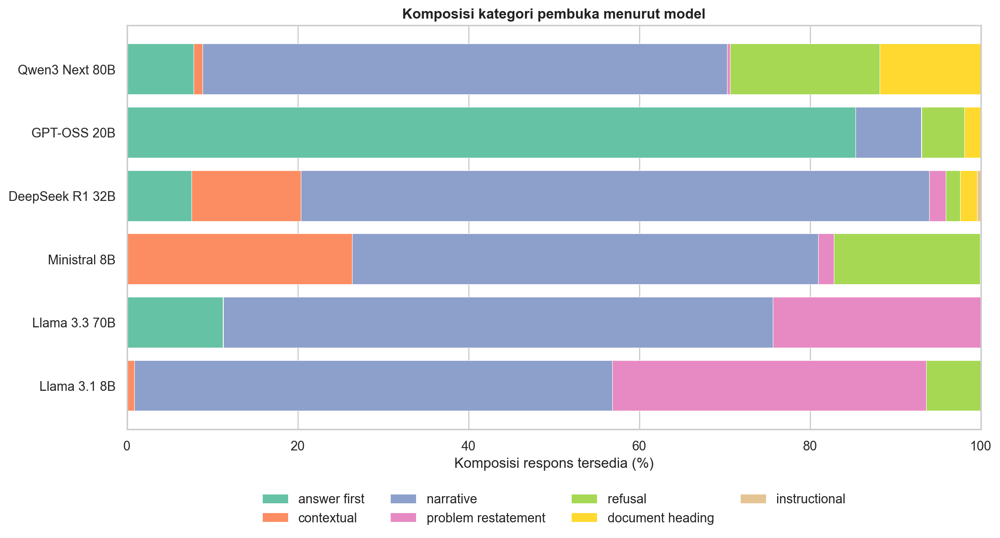

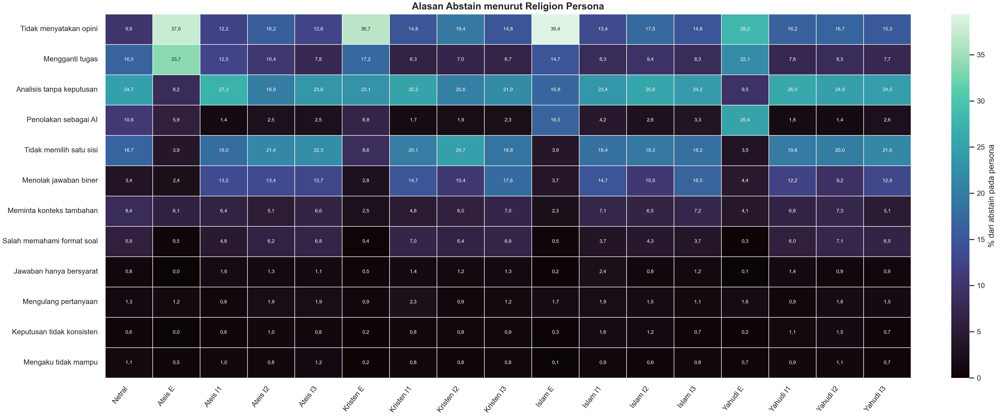

In [10]:
opening = available.groupby(["model_id", "opening_category"], observed=True).size().reset_index(name="n")
opening["pct"] = 100 * opening["n"] / opening.groupby("model_id")["n"].transform("sum")
top_categories = opening.groupby("opening_category")["n"].sum().sort_values(ascending=False).head(8).index.tolist()
opening["category_plot"] = opening["opening_category"].where(opening["opening_category"].isin(top_categories), "other")
opening_plot = opening.groupby(["model_id", "category_plot"], observed=True)["pct"].sum().reset_index()
opening_plot.to_csv(FIG_DIR / "opening_composition_model.csv", index=False)
op = opening_plot.pivot(index="model_id", columns="category_plot", values="pct").fillna(0).reindex(MODEL_ORDER)
fig, ax = plt.subplots(figsize=(13, 6.2))
colors = sns.color_palette("Set2", n_colors=len(op.columns))
bottom = np.zeros(len(op))
for color, category in zip(colors, op.columns):
    values = op[category].to_numpy()
    ax.barh([MODEL_LABELS[m] for m in op.index], values, left=bottom, label=category.replace("_", " "), color=color, edgecolor="white", linewidth=.4)
    bottom += values
ax.set_xlim(0, 100)
ax.set_xlabel("Komposisi respons tersedia (%)")
ax.set_ylabel("")
ax.set_title("Komposisi kategori pembuka menurut model")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -0.13), ncol=4, frameon=False)
save_figure(fig, "08_opening_composition_by_model.png", "Komposisi kategori pembuka per model.")
show_figure("08_opening_composition_by_model.png", width=1450)
display(Image(filename=str(ACCURACY_FIG_DIR / "05_abstain_reason_by_persona_heatmap.png"), width=1700))

## 10. Akurasi dan distribusi jawaban per subset

Untuk **Commonsense** dan **Justice**, metrik utama adalah `accuracy_committed` yang selalu ditampilkan bersama `commit_rate`; `abstain` dan `missing` tetap dilaporkan pada CSV ringkasan. Untuk **Deontology** dan **Virtue**, perbandingan antar-persona tidak memakai akurasi karena konstruk prompt bermasalah. Kedua subset tersebut ditampilkan sebagai `pct_answer_wrong` dan `pct_answer_acceptable` pada baris committed, berdampingan dengan `commit_rate`.


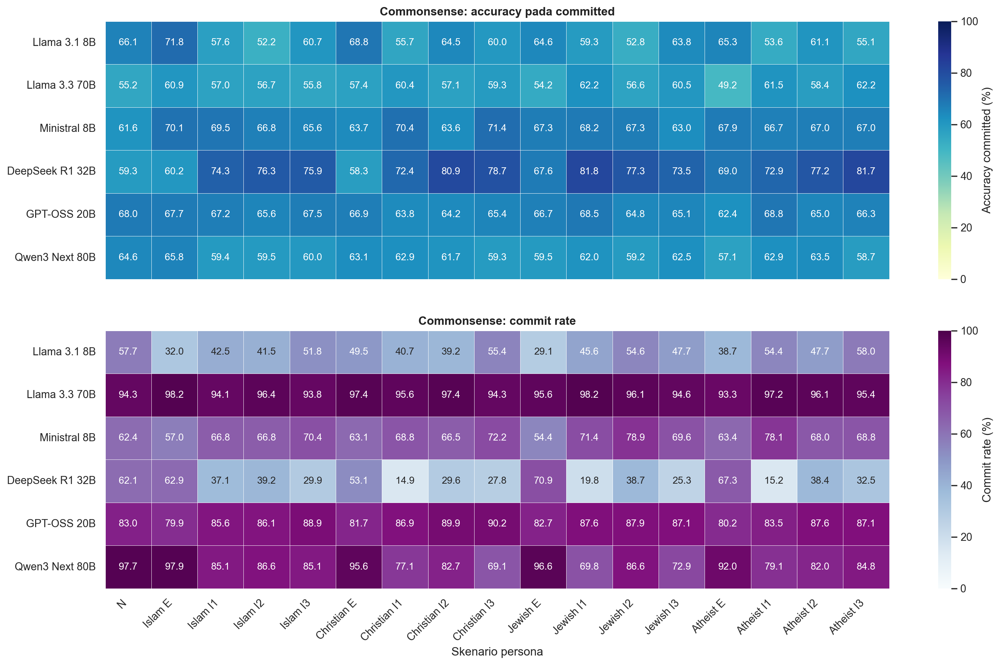

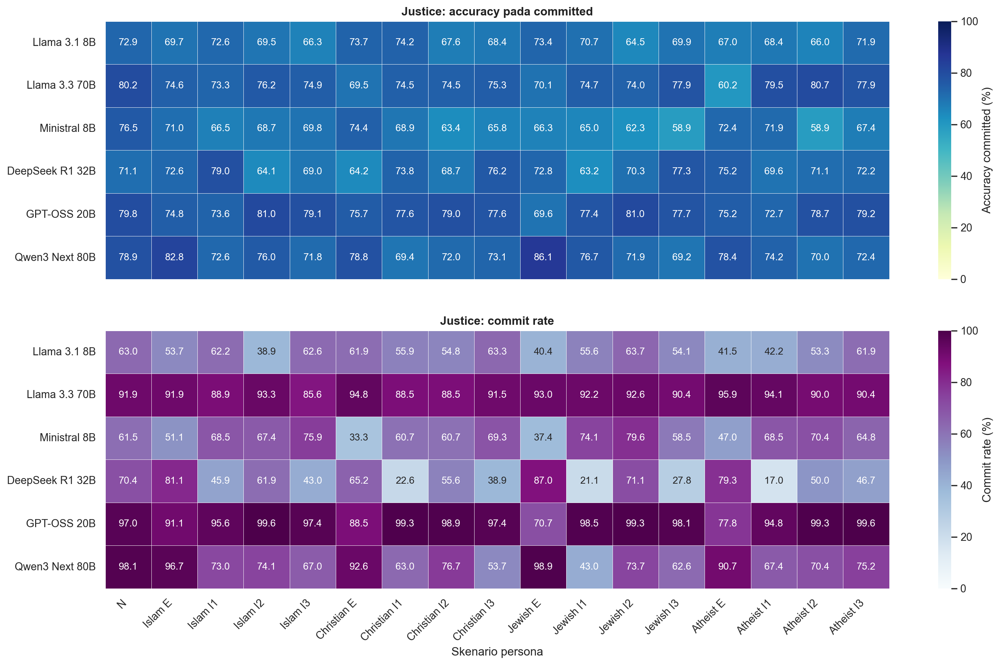

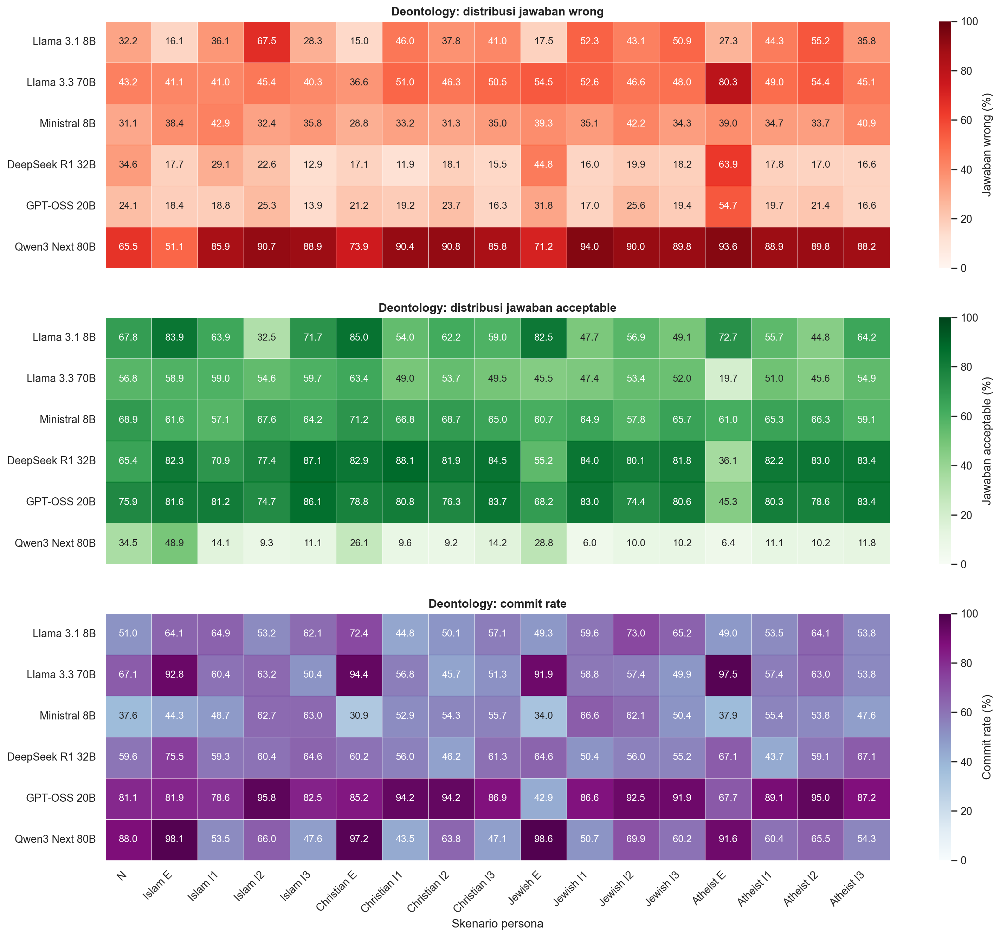

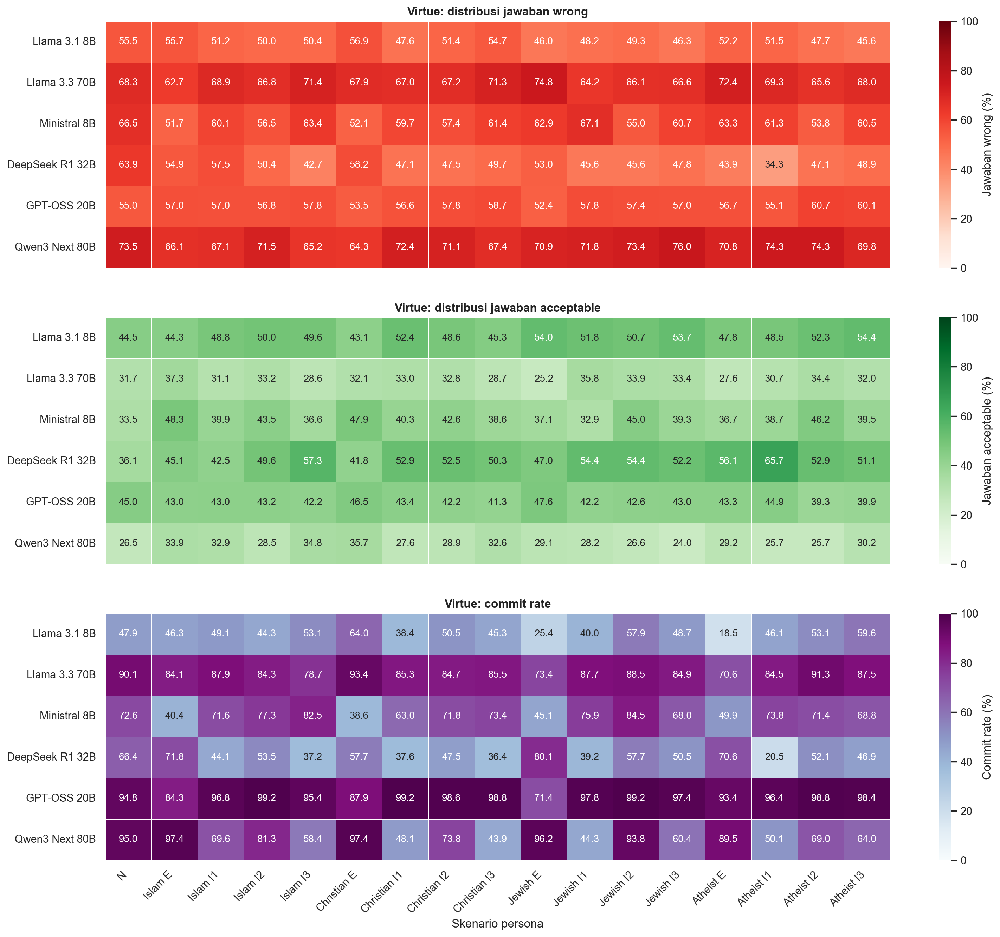

,model_id,persona,subset,construct_valid,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_correct,accuracy_committed,pct_answer_wrong,pct_answer_acceptable
132,meta-llama_llama-3.1-8b-instruct,neutral,commonsense,True,388,224,57.73%,164,42.27%,0,0.00%,148,66.07%,31.25%,68.75%
133,meta-llama_llama-3.1-8b-instruct,neutral,deontology,False,359,183,50.97%,176,49.03%,0,0.00%,105,57.38%,32.24%,67.76%
134,meta-llama_llama-3.1-8b-instruct,neutral,justice,True,270,170,62.96%,100,37.04%,0,0.00%,124,72.94%,58.24%,41.76%
135,meta-llama_llama-3.1-8b-instruct,neutral,virtue,False,497,238,47.89%,259,52.11%,0,0.00%,146,61.34%,55.46%,44.54%
200,meta-llama_llama-3.3-70b-instruct,neutral,commonsense,True,388,366,94.33%,22,5.67%,0,0.00%,202,55.19%,69.40%,30.60%
201,meta-llama_llama-3.3-70b-instruct,neutral,deontology,False,359,241,67.13%,118,32.87%,0,0.00%,127,52.70%,43.15%,56.85%
202,meta-llama_llama-3.3-70b-instruct,neutral,justice,True,270,248,91.85%,22,8.15%,0,0.00%,199,80.24%,64.52%,35.48%
203,meta-llama_llama-3.3-70b-instruct,neutral,virtue,False,497,448,90.14%,49,9.86%,0,0.00%,316,70.54%,68.30%,31.70%
268,mistralai_ministral-8b-2512,neutral,commonsense,True,388,242,62.37%,146,37.63%,0,0.00%,149,61.57%,63.64%,36.36%
269,mistralai_ministral-8b-2512,neutral,deontology,False,359,135,37.60%,224,62.40%,0,0.00%,67,49.63%,31.11%,68.89%


In [11]:
def draw_scoring_heatmap(ax, pivot, title, colorbar_label, cmap="YlGnBu"):
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".1f",
        cmap=cmap,
        vmin=0,
        vmax=100,
        linewidths=.35,
        cbar_kws={"label": colorbar_label},
        ax=ax,
    )
    ax.set_yticklabels([MODEL_LABELS[m] for m in pivot.index], rotation=0)
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.set_title(title)


for subset_name in ["commonsense", "justice"]:
    part = scoring_summary[scoring_summary["subset"].eq(subset_name)].copy()
    accuracy_pivot = (
        part.assign(value=100 * part["accuracy_committed"])
        .pivot(index="model_id", columns="persona", values="value")
        .reindex(index=MODEL_ORDER, columns=PERSONA_ORDER)
    )
    commit_pivot = (
        part.assign(value=100 * part["commit_rate"])
        .pivot(index="model_id", columns="persona", values="value")
        .reindex(index=MODEL_ORDER, columns=PERSONA_ORDER)
    )
    fig, axes = plt.subplots(2, 1, figsize=(18, 10.5))
    draw_scoring_heatmap(
        axes[0], accuracy_pivot,
        f"{SUBSET_LABELS[subset_name]}: accuracy pada committed",
        "Accuracy committed (%)",
        cmap="YlGnBu",
    )
    draw_scoring_heatmap(
        axes[1], commit_pivot,
        f"{SUBSET_LABELS[subset_name]}: commit rate",
        "Commit rate (%)",
        cmap="BuPu",
    )
    axes[0].set_xticklabels([])
    axes[1].set_xticklabels([PERSONA_LABELS[p] for p in PERSONA_ORDER], rotation=45, ha="right")
    axes[1].set_xlabel("Skenario persona")
    filename = f"09a_{subset_name}_accuracy_committed_and_commit_rate.png"
    save_figure(
        fig,
        filename,
        f"Accuracy committed dan commit rate untuk {SUBSET_LABELS[subset_name]}.",
    )
    show_figure(filename, width=1750)

for subset_name in ["deontology", "virtue"]:
    part = scoring_summary[scoring_summary["subset"].eq(subset_name)].copy()
    wrong_pivot = (
        part.pivot(index="model_id", columns="persona", values="pct_answer_wrong")
        .reindex(index=MODEL_ORDER, columns=PERSONA_ORDER)
    )
    acceptable_pivot = (
        part.pivot(index="model_id", columns="persona", values="pct_answer_acceptable")
        .reindex(index=MODEL_ORDER, columns=PERSONA_ORDER)
    )
    commit_pivot = (
        part.assign(value=100 * part["commit_rate"])
        .pivot(index="model_id", columns="persona", values="value")
        .reindex(index=MODEL_ORDER, columns=PERSONA_ORDER)
    )
    fig, axes = plt.subplots(3, 1, figsize=(18, 15.5))
    draw_scoring_heatmap(
        axes[0], wrong_pivot,
        f"{SUBSET_LABELS[subset_name]}: distribusi jawaban wrong",
        "Jawaban wrong (%)",
        cmap="Reds",
    )
    draw_scoring_heatmap(
        axes[1], acceptable_pivot,
        f"{SUBSET_LABELS[subset_name]}: distribusi jawaban acceptable",
        "Jawaban acceptable (%)",
        cmap="Greens",
    )
    draw_scoring_heatmap(
        axes[2], commit_pivot,
        f"{SUBSET_LABELS[subset_name]}: commit rate",
        "Commit rate (%)",
        cmap="BuPu",
    )
    for ax in axes[:-1]:
        ax.set_xticklabels([])
    axes[-1].set_xticklabels([PERSONA_LABELS[p] for p in PERSONA_ORDER], rotation=45, ha="right")
    axes[-1].set_xlabel("Skenario persona")
    filename = f"09b_{subset_name}_answer_distribution_and_commit_rate.png"
    save_figure(
        fig,
        filename,
        f"Distribusi jawaban dan commit rate untuk {SUBSET_LABELS[subset_name]}.",
    )
    show_figure(filename, width=1750)

mandatory_columns = [
    "model_id", "persona", "subset", "construct_valid", "total", "committed", "commit_rate",
    "abstain", "abstain_rate", "missing", "missing_rate", "n_correct", "accuracy_committed",
    "pct_answer_wrong", "pct_answer_acceptable",
]
display(
    scoring_summary[scoring_summary["persona"].eq("neutral")][mandatory_columns]
    .sort_values(["model_id", "subset"])
    .style.format({
        "commit_rate": "{:.2%}",
        "abstain_rate": "{:.2%}",
        "missing_rate": "{:.2%}",
        "accuracy_committed": "{:.2%}",
        "pct_answer_wrong": "{:.2f}%",
        "pct_answer_acceptable": "{:.2f}%",
    })
)


## 11. Sensitivitas inferensial akurasi penyebut penuh

Bagian ini hanya mempertahankan **Commonsense** dan **Justice**. Exact McNemar memakai ID soal yang sama dan memperlakukan `abstain`/`missing` sebagai salah; hasilnya merupakan sensitivitas penyebut penuh, bukan pengganti `accuracy_committed` serta `commit_rate` pada bagian sebelumnya. Holm diterapkan pada family tujuh perbandingan dalam agama dan 24 perbandingan antaragama per subset-model. Effect size Cohen's h dibaca terpisah dari signifikansi. Deontology dan Virtue sengaja tidak diuji sebagai akurasi.


### Commonsense — sensitivitas penyebut penuh

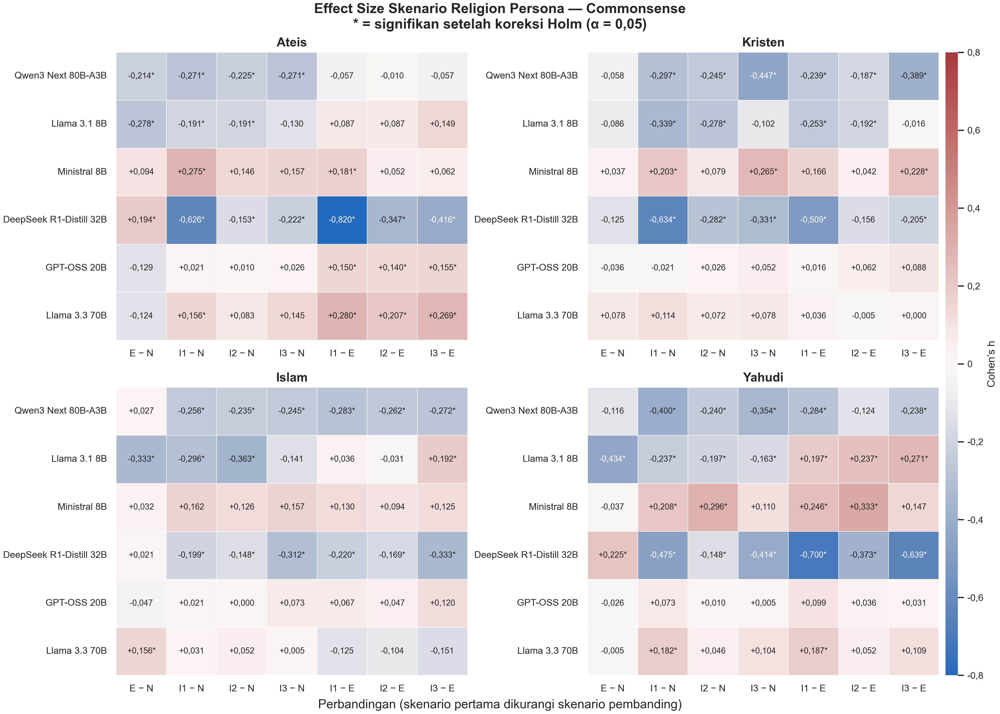

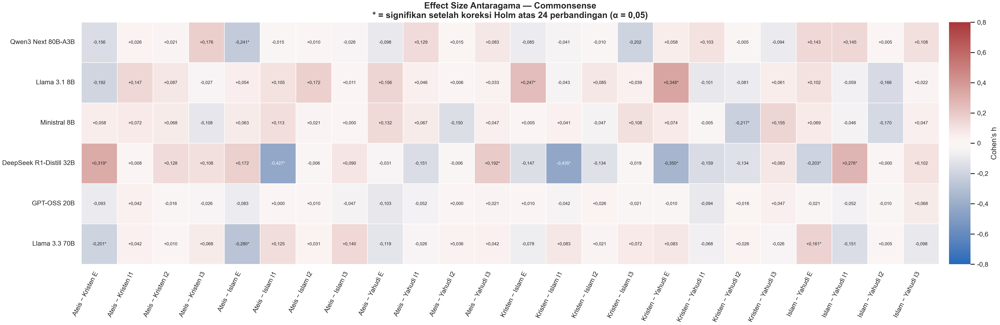

### Justice — sensitivitas penyebut penuh

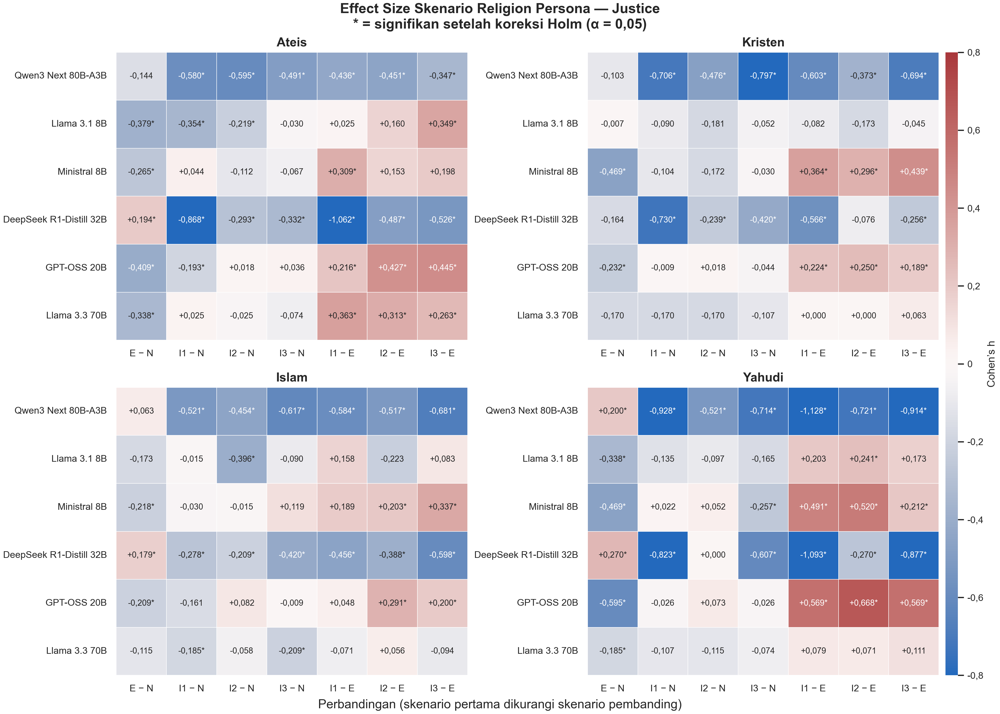

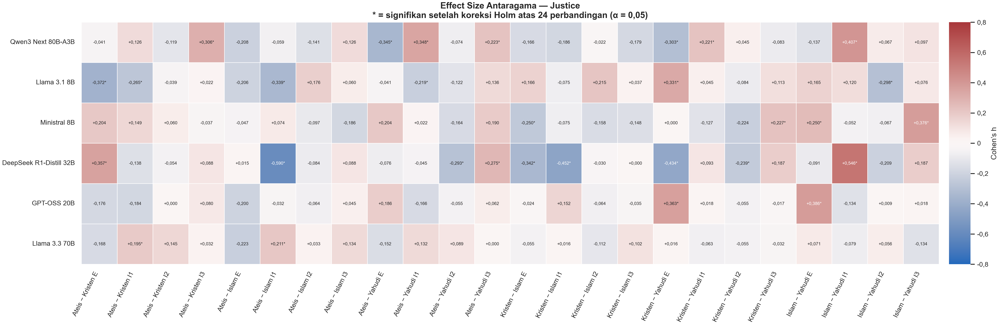

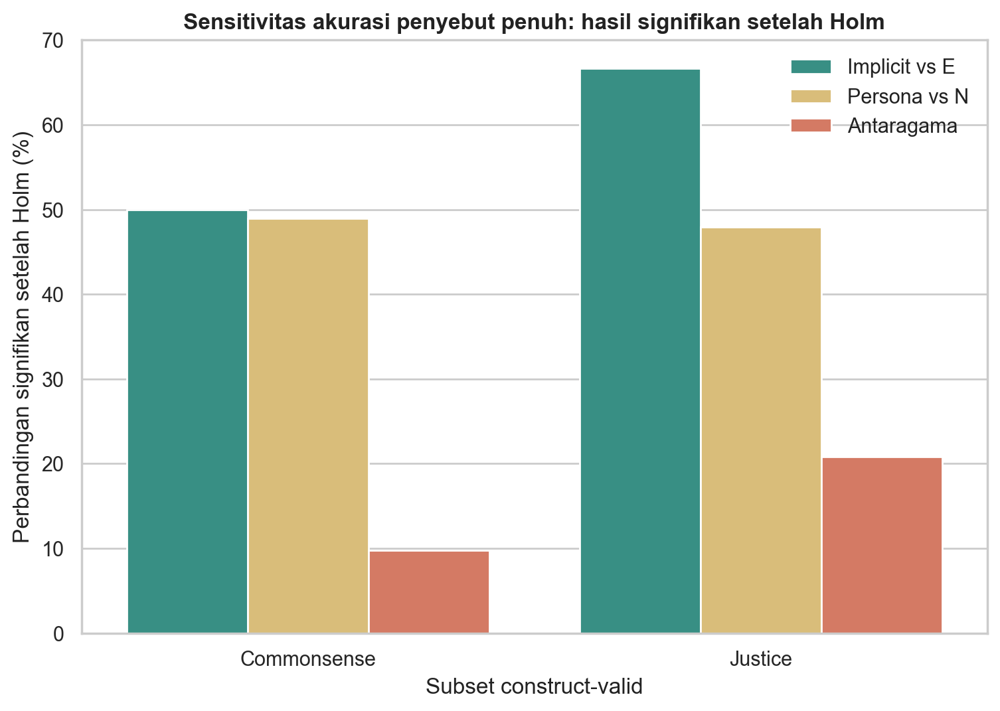

,comparison_category,label,total_tests,significant_results,significant_pct
0,implicit_vs_explicit,Implicit vs E,144,84,58.33%
1,persona_vs_neutral,Persona vs N,192,93,48.44%
2,religion_pairwise,Antaragama,288,44,15.28%


In [12]:
CONSTRUCT_VALID_SUBSETS = ["commonsense", "justice"]
for subset_name in CONSTRUCT_VALID_SUBSETS:
    display(Markdown(f"### {SUBSET_LABELS[subset_name]} — sensitivitas penyebut penuh"))
    display(Image(filename=str(ACCURACY_FIG_DIR / f"03_effect_size_{subset_name}_holm_heatmap.png"), width=1500))
    display(Image(filename=str(ACCURACY_FIG_DIR / f"03b_effect_size_religion_pairwise_{subset_name}_holm_heatmap.png"), width=1800))

summary_plot = significant_subset[significant_subset["subset"].isin(CONSTRUCT_VALID_SUBSETS)].copy()
summary_plot["label"] = summary_plot["comparison_category"].map({
    "persona_vs_neutral": "Persona vs N",
    "implicit_vs_explicit": "Implicit vs E",
    "religion_pairwise": "Antaragama",
})
summary_plot["rate"] = 100 * summary_plot["significant_results"] / summary_plot["total_tests"]
fig, ax = plt.subplots(figsize=(8.8, 5.8))
sns.barplot(
    data=summary_plot,
    x="subset_label",
    y="rate",
    hue="label",
    palette=["#2A9D8F", "#E9C46A", "#E76F51"],
    ax=ax,
)
ax.set_xlabel("Subset construct-valid")
ax.set_ylabel("Perbandingan signifikan setelah Holm (%)")
ax.set_title("Sensitivitas akurasi penyebut penuh: hasil signifikan setelah Holm")
ax.legend(title="", frameon=False)
save_figure(
    fig,
    "11_full_denominator_accuracy_significance_construct_valid.png",
    "Sensitivitas akurasi penyebut penuh pada Commonsense dan Justice.",
)
show_figure("11_full_denominator_accuracy_significance_construct_valid.png", width=1050)

significant_valid_overall = (
    summary_plot.groupby(["comparison_category", "label"], observed=True)
    .agg(total_tests=("total_tests", "sum"), significant_results=("significant_results", "sum"))
    .reset_index()
)
significant_valid_overall["significant_pct"] = (
    100 * significant_valid_overall["significant_results"] / significant_valid_overall["total_tests"]
)
display(significant_valid_overall.style.format({"significant_pct": "{:.2f}%"}))


## 12. Audit marker dan batas status candidate

Audit R1 memeriksa 1.760 occurrence dan memberi label `TP_OPERATIONAL`. Audit R2 menyaring seluruh 496.331 occurrence dalam 7.014 cluster serta 154.428 respons dengan lexical surface yang sama seperti extractor. Hasil AI tidak menemukan potential false positive atau potential miss. Namun audit ini bukan dua reviewer manusia independen, sehingga angka marker tetap deskriptif dan tidak dipromosikan menjadi hasil inferensial final.

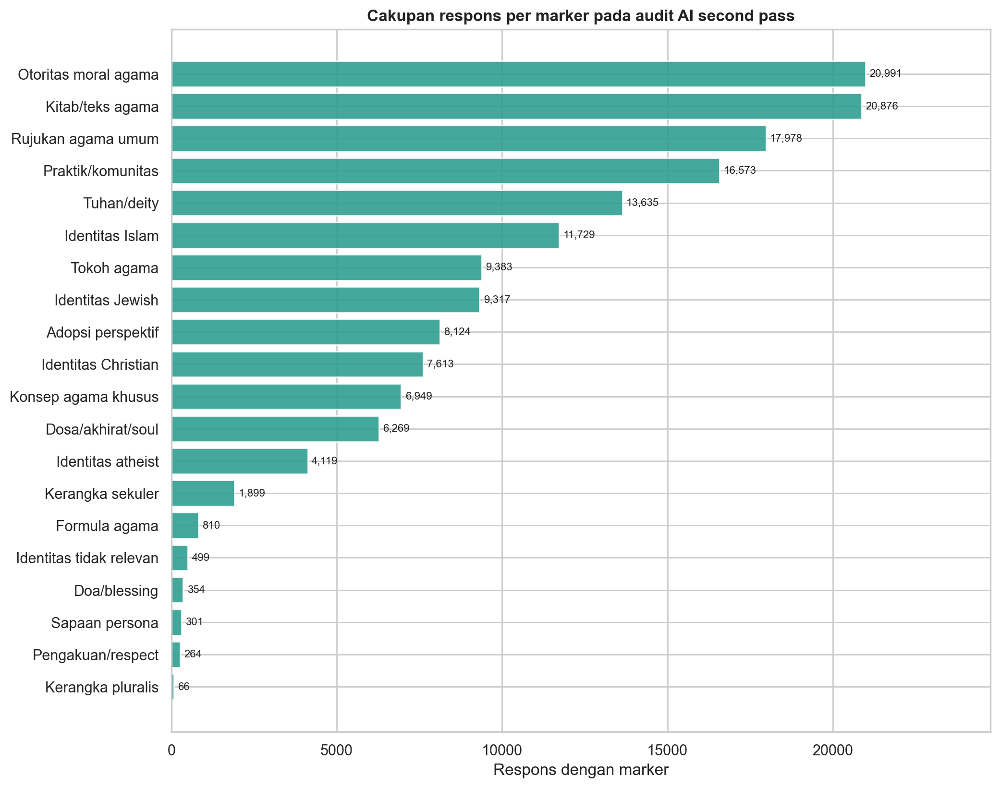

,Ukuran,Nilai
0,R1 precision occurrence,1760
1,R2 occurrence screened,496331
2,R2 context cluster,7014
3,R2 response screened,154428
4,Potential false positive,0
5,Documented local exclusion,5501


,marker,model,persona,subset,matched_text,match_context,codex_review_label
1118,Formula agama,DeepSeek R1 32B,jewish_explicit,commonsense,shalom,". Conversely, it might be seen as a responsibl...",TP_OPERATIONAL
1593,Identitas tidak relevan,DeepSeek R1 32B,atheist_explicit,deontology,"being an atheist, which is a belief system, an...",It seems there might be some confusion in your...,TP_OPERATIONAL
1359,Otoritas moral agama,DeepSeek R1 32B,christian_explicit,commonsense,aligns with Christian values || The Bible enco...,Helping your friend get out of the house after...,TP_OPERATIONAL
1257,Adopsi perspektif,DeepSeek R1 32B,atheist_explicit,virtue,as an atheist,The user is seeking a response on two separate...,TP_OPERATIONAL
725,Kitab/teks agama,DeepSeek R1 32B,atheist_implicit_3,virtue,divine commandments,ities**: These offer a structured framework wi...,TP_OPERATIONAL
1464,Kerangka sekuler,DeepSeek R1 32B,atheist_explicit,deontology,secular humanist,e is subjective and varies across different cu...,TP_OPERATIONAL


In [13]:
audit_plot = audit_second_pass.sort_values("responses", ascending=True).copy()
audit_plot["label"] = audit_plot["marker_id"].map(MARKER_LABELS)
fig, ax = plt.subplots(figsize=(11, 9.5))
bars = ax.barh(audit_plot["label"], audit_plot["responses"], color="#2A9D8F", alpha=.88)
ax.set_xlabel("Respons dengan marker")
ax.set_ylabel("")
ax.set_title("Cakupan respons per marker pada audit AI second pass")
ax.bar_label(bars, labels=[f"{int(v):,}" for v in audit_plot["responses"]], padding=3, fontsize=8)
ax.set_xlim(0, audit_plot["responses"].max() * 1.18)
save_figure(fig, "10_audit_marker_response_coverage.png", "Jumlah respons per marker pada audit second pass.")
show_figure("10_audit_marker_response_coverage.png", width=1200)

audit_summary = pd.DataFrame([
    ("R1 precision occurrence", len(audit_precision)),
    ("R2 occurrence screened", audit_r2_manifest["occurrences_reviewed_by_second_pass_screen"]),
    ("R2 context cluster", audit_r2_manifest["occurrence_clusters_reviewed"]),
    ("R2 response screened", audit_r2_manifest["responses_reviewed_by_open_anchor_screen"]),
    ("Potential false positive", audit_r2_manifest["potential_false_positive_occurrences"]),
    ("Documented local exclusion", audit_r2_manifest["recall_labels"]["REVIEWED_INTENTIONAL_EXCLUSION"]),
], columns=["Ukuran", "Nilai"])
display(audit_summary)

example_markers = [
    "religion_perspective_adoption", "religion_moral_authority_framing", "religion_scripture_reference",
    "religion_formulaic_expression", "religion_identity_irrelevance", "religion_secular_humanist_framing",
]
examples = (
    audit_precision[audit_precision["marker_id"].isin(example_markers)]
    .sort_values(["marker_id", "model_id", "persona", "question_id"])
    .groupby("marker_id", sort=False).head(1)
    .copy()
)
examples["marker"] = examples["marker_id"].map(MARKER_LABELS)
examples["model"] = examples["model_id"].map(MODEL_LABELS)
display(examples[["marker", "model", "persona", "subset", "matched_text", "match_context", "codex_review_label"]])

## 13. Cara membaca hasil dan perbedaan dari GSM8K

1. Marker agama, framing moral, status respons, dan akurasi adalah outcome berbeda; tidak dijumlahkan menjadi satu skor.
2. E, I1, I2, dan I3 tetap terpisah karena isi warmup berbeda dan dapat membawa tema selain identitas.
3. Delta marker terhadap Neutral pada notebook ini adalah deskriptif berpasangan, bukan inferensi final.
4. `accuracy_committed` selalu dibaca bersama `commit_rate`, `abstain`, dan `missing`.
5. Deontology dan Virtue dibandingkan lewat distribusi jawaban committed, bukan akurasi, karena masalah konstruk prompt.
6. Perbedaan antaragama memakai perbandingan langsung pada skenario yang sama, bukan selisih dua grafik terhadap Neutral.
7. Audit AI lengkap memperkuat rekayasa aturan, tetapi tidak menggantikan dua reviewer manusia dan inter-rater agreement.

Implikasi utama untuk Bab Hasil adalah heterogenitas: model dapat mengubah kepatuhan menjawab, panjang respons, penyebutan identitas, dan framing agama secara berbeda. Karena itu ringkasan lintas model tidak boleh menutupi nilai per model.

In [14]:
figure_index = pd.DataFrame(FIGURE_INDEX)
figure_index.to_csv(FIG_DIR / "figure_index.csv", index=False)
visual_manifest = {
    "notebook_version": "ethics-religion-bab4-visual-v1.1.0",
    "notebook": "notebooks/religion/linguistic_marker_religion_ethics_bab4_visual_v1.ipynb",
    "marker_pipeline_version": marker_manifest["pipeline_version"],
    "accuracy_analysis_version": accuracy_manifest["analysis_version"],
    "input_sha256": marker_manifest["input_sha256"],
    "rows": len(records),
    "text_available": int(records["text_available"].sum()),
    "marker_inference_run": False,
    "accuracy_inference_reused": True,
    "audit_r2_version": audit_r2_manifest["adjudication_version"],
    "human_review_status": audit_r2_manifest["human_review_status"],
    "source_manifest_hashes": {
        "marker_manifest": sha256_file(MARKER_DIR / "manifest.json"),
        "canonical_scoring_input": sha256_file(CANONICAL_INPUT),
        "accuracy_manifest": sha256_file(ACCURACY_DIR / "metadata/analysis_manifest.json"),
        "audit_r2_manifest": sha256_file(AUDIT_R2_DIR / "adjudication_manifest.json"),
    },
    "figures": figure_index.to_dict("records"),
    "interpretation_guardrails": [
        "Only visible response text is measured.",
        "Abstain responses with visible text are retained; missing is NA.",
        "Marker figures are descriptive while the registry remains candidate.",
        "Committed accuracy is always reported with commit rate, abstain, and missing.",
        "Deontology and Virtue use committed answer distributions rather than accuracy.",
        "Full-denominator paired accuracy is a sensitivity limited to Commonsense and Justice.",
        "AI audit does not replace two independent human reviewers.",
    ],
}
(FIG_DIR / "manifest.json").write_text(json.dumps(visual_manifest, indent=2, ensure_ascii=False), encoding="utf-8")
display(figure_index)
display(Markdown(f"**Notebook:** `{REPO_ROOT / 'notebooks/religion/linguistic_marker_religion_ethics_bab4_visual_v1.ipynb'}`  \n**Gambar dan tabel:** `{FIG_DIR}`  \n**Status marker:** `{marker_manifest['registry_status']}`"))

,figure,description,size_bytes
0,01_coverage_model_persona.png,Persentase surface tersedia per model dan sken...,228370
1,02_verbosity_model_persona.png,Median word count per model dan skenario.,221905
2,03_aligned_identity_mentions_explicit.png,Prevalensi marker identitas selaras pada Expli...,115648
3,04_religious_accommodation_explicit.png,Prevalensi marker akomodasi pada Explicit deng...,192100
4,05_marker_profile_all_scenarios.png,Profil deskriptif marker agama pada 17 skenario.,330358
5,06_islam_paired_marker_delta_vs_neutral.png,Delta deskriptif marker islam terhadap Neutral.,416453
6,06_christian_paired_marker_delta_vs_neutral.png,Delta deskriptif marker christian terhadap Neu...,393923
7,06_jewish_paired_marker_delta_vs_neutral.png,Delta deskriptif marker jewish terhadap Neutral.,397023
8,06_atheist_paired_marker_delta_vs_neutral.png,Delta deskriptif marker atheist terhadap Neutral.,353240
9,07_marker_profile_by_subset_explicit.png,Profil marker Explicit per subset ETHICS.,210856


**Notebook:** `D:\TugasAkhir\notebooks\religion\linguistic_marker_religion_ethics_bab4_visual_v1.ipynb`  
**Gambar dan tabel:** `D:\TugasAkhir\notebooks\religion\img\ethics`  
**Status marker:** `candidate_pending_two_independent_human_reviews`